# 01 — Exploratory Data Analysis: Nouakchott electricity demand

> ⚠️ **Prototype data.** Every figure in this notebook is computed on **synthetic** data produced by
> `src/ingestion/synthetic.py`. It is **not SOMELEC data** and says nothing about real consumption in
> Nouakchott. The goal is to (1) check that the synthetic data has the structure a forecasting system must
> handle, and (2) establish the analysis workflow that would be re-run on real data.

Data is read from PostgreSQL (`raw.energy_demand`, loaded by `python -m src.ingestion.load_data`), with a
CSV fallback if the database is not running.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf

from src.data.repository import load_raw_energy, load_synthetic_events
from src.db.engine import check_connection, get_engine
from src.ingestion.csv_loader import load_source_mapping, read_source_csv
from src.ingestion.validation import validate_energy_data
from src.visualization.style import SERIES, SEQUENTIAL, STATUS, INK_MUTED, apply_style, add_source_note

apply_style()
pd.set_option("display.precision", 2)

try:
    engine = get_engine(); check_connection(engine)
    df = load_raw_energy("synthetic", engine)
    events = load_synthetic_events(engine)
    origin = "PostgreSQL raw.energy_demand"
except Exception as exc:
    print("DB unavailable, using CSV:", exc)
    df = read_source_csv(load_source_mapping("synthetic"))
    events = pd.read_csv(ROOT / "data/raw/synthetic_events.csv", parse_dates=["start", "end"])
    origin = "CSV data/raw/synthetic_energy_demand.csv"

s = df.set_index("timestamp")
print(f"Source: {origin}")
print(f"Rows: {len(df):,} | period: {s.index.min()} -> {s.index.max()} | columns: {list(df.columns)}")

Source: PostgreSQL raw.energy_demand
Rows: 26,304 | period: 2023-09-01 00:00:00+00:00 -> 2026-08-31 23:00:00+00:00 | columns: ['timestamp', 'demand_mw', 'temperature_c', 'humidity', 'wind_speed', 'cloud_cover']


## 1. Overview and data quality

In [2]:
s.describe().T

,count,mean,std,min,25%,50%,75%,max
demand_mw,26304.0,178.87,29.48,45.36,155.41,179.28,199.1,331.4
temperature_c,26304.0,25.56,5.06,11.30,22.10,26.10,29.6,40.4
humidity,26304.0,56.98,14.18,12.80,46.10,56.80,67.6,100.0
wind_speed,26304.0,4.85,1.69,0.00,3.70,4.80,6.0,11.1
cloud_cover,26304.0,20.44,14.34,0.00,9.30,18.60,30.1,68.1


In [3]:
report = validate_energy_data(df)
pd.DataFrame(
    [{"check": c.name, "severity": c.severity, "passed": c.passed, "message": c.message} for c in report.checks]
)

,check,severity,passed,message
0,required_columns,error,True,All required columns present
1,timestamps_parseable,error,True,All timestamps parsed
2,duplicate_timestamps,error,True,No duplicate timestamps
3,frequency,error,True,Regular 0 days 01:00:00 frequency
4,missing_timestamps,warning,True,No gaps in the hourly series
5,null_values,warning,True,No null values
6,negative_values,error,True,No negative values
7,physical_bounds,error,True,All values within physical bounds
8,demand_outliers,warning,False,127 potential demand outliers (|robust z| > 5.0)


In [4]:
expected = pd.date_range(s.index.min(), s.index.max(), freq="h")
print("Missing hours:", len(expected.difference(s.index)))
print("Null values per column:"); print(s.isna().sum().to_string())

Missing hours: 0
Null values per column:
demand_mw        0
temperature_c    0
humidity         0
wind_speed       0
cloud_cover      0


## 2. Demand over time

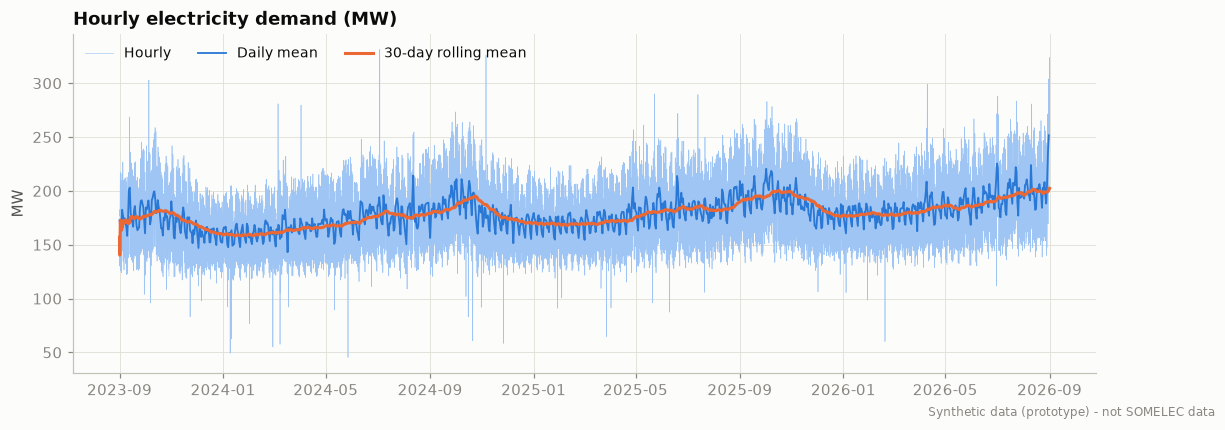

Monthly mean, first 12 months vs last 12 months: 170.0 MW -> 188.1 MW (+10.7% over 2 years)


In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s.index, s["demand_mw"], color=SEQUENTIAL[1], lw=0.4, label="Hourly")
ax.plot(s["demand_mw"].resample("D").mean(), color=SERIES[0], lw=1.2, label="Daily mean")
ax.plot(s["demand_mw"].rolling("30D").mean(), color=SERIES[1], lw=2, label="30-day rolling mean")
ax.set_title("Hourly electricity demand (MW)")
ax.set_ylabel("MW"); ax.legend(loc="upper left", ncols=3)
add_source_note(fig); plt.show()

yearly = s["demand_mw"].resample("YE").mean()
growth = s["demand_mw"].resample("MS").mean()
print("Monthly mean, first 12 months vs last 12 months: "
      f"{growth.iloc[:12].mean():.1f} MW -> {growth.iloc[-12:].mean():.1f} MW "
      f"({growth.iloc[-12:].mean() / growth.iloc[:12].mean() - 1:+.1%} over 2 years)")

## 3. Seasonal profiles: hour, day of week, month

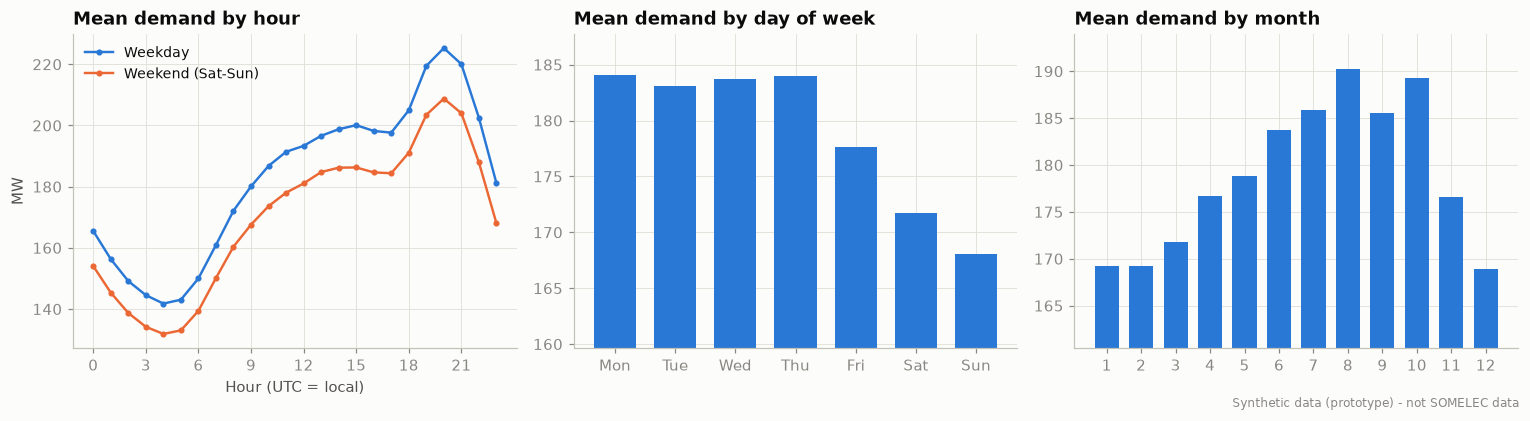

Peak hour: 20 h | trough hour: 4 h
Weekend vs weekday: -7.5%
Hottest-season month / coolest month: +12.6% (8 vs 12)


In [6]:
d = s.assign(hour=s.index.hour, dow=s.index.dayofweek, month=s.index.month,
             weekend=s.index.dayofweek >= 5)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

prof = d.groupby(["hour", "weekend"])["demand_mw"].mean().unstack()
axes[0].plot(prof.index, prof[False], color=SERIES[0], marker="o", ms=3, label="Weekday")
axes[0].plot(prof.index, prof[True], color=SERIES[1], marker="o", ms=3, label="Weekend (Sat-Sun)")
axes[0].set_title("Mean demand by hour"); axes[0].set_xlabel("Hour (UTC = local)"); axes[0].set_ylabel("MW")
axes[0].set_xticks(range(0, 24, 3)); axes[0].legend()

dow = d.groupby("dow")["demand_mw"].mean()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values, color=SERIES[0], width=0.7)
axes[1].set_ylim(dow.min() * 0.95, dow.max() * 1.02)
axes[1].set_title("Mean demand by day of week")

mon = d.groupby("month")["demand_mw"].mean()
axes[2].bar(range(1, 13), mon.values, color=SERIES[0], width=0.7)
axes[2].set_ylim(mon.min() * 0.95, mon.max() * 1.02)
axes[2].set_xticks(range(1, 13)); axes[2].set_title("Mean demand by month")
fig.tight_layout(); add_source_note(fig); plt.show()

print("Peak hour:", prof[False].idxmax(), "h | trough hour:", prof[False].idxmin(), "h")
print(f"Weekend vs weekday: {dow.loc[[5, 6]].mean() / dow.loc[0:3].mean() - 1:+.1%}")
print(f"Hottest-season month / coolest month: {mon.max() / mon.min() - 1:+.1%} ({mon.idxmax()} vs {mon.idxmin()})")

Note: the bar charts use a truncated y-axis to make the relative differences visible; the printed ratios give the actual magnitudes.

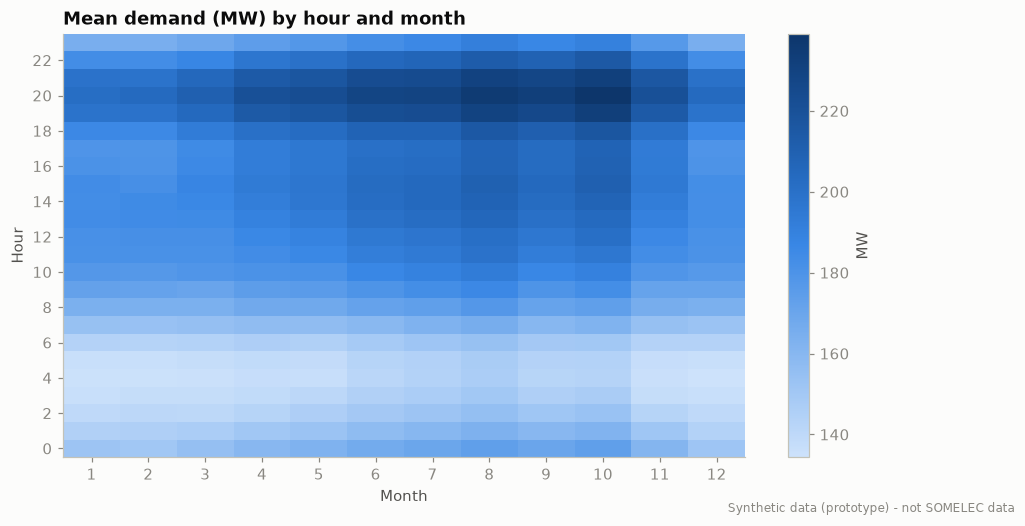

In [7]:
heat = d.pivot_table(index="hour", columns="month", values="demand_mw", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 5))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blue_seq", SEQUENTIAL)
im = ax.imshow(heat.values, aspect="auto", cmap=cmap, origin="lower")
ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(0, 24, 2), range(0, 24, 2))
ax.set_xlabel("Month"); ax.set_ylabel("Hour"); ax.grid(False)
ax.set_title("Mean demand (MW) by hour and month")
fig.colorbar(im, ax=ax, label="MW"); add_source_note(fig); plt.show()

## 4. Distribution

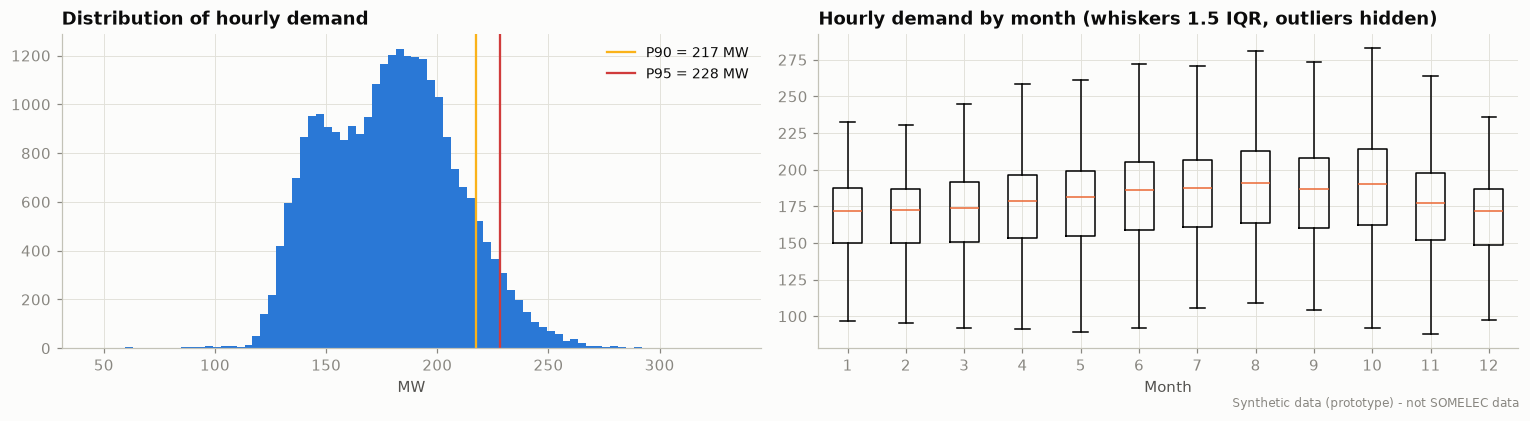

Skewness: 0.19 | kurtosis: -0.20


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(s["demand_mw"], bins=80, color=SERIES[0])
for q, c in [(0.90, STATUS["warning"]), (0.95, STATUS["critical"])]:
    v = s["demand_mw"].quantile(q)
    axes[0].axvline(v, color=c, lw=1.5, label=f"P{int(q*100)} = {v:.0f} MW")
axes[0].set_title("Distribution of hourly demand"); axes[0].set_xlabel("MW"); axes[0].legend()

box = [d.loc[d.month == m, "demand_mw"].values for m in range(1, 13)]
axes[1].boxplot(box, tick_labels=range(1, 13), showfliers=False, medianprops={"color": SERIES[1]})
axes[1].set_title("Hourly demand by month (whiskers 1.5 IQR, outliers hidden)"); axes[1].set_xlabel("Month")
fig.tight_layout(); add_source_note(fig); plt.show()
print(f"Skewness: {s['demand_mw'].skew():.2f} | kurtosis: {s['demand_mw'].kurt():.2f}")

## 5. Seasonality structure: autocorrelation and decomposition

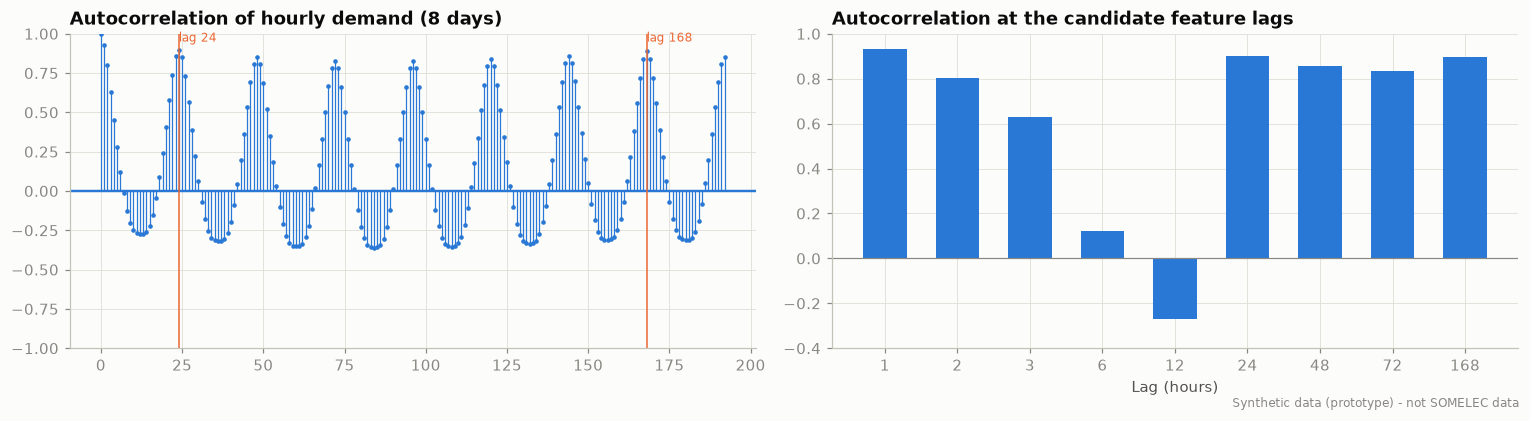

1      0.93
2      0.80
3      0.63
6      0.12
12    -0.27
24     0.90
48     0.86
72     0.84
168    0.90


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
plot_acf(s["demand_mw"], lags=24 * 8, ax=axes[0], markersize=2, color=SERIES[0],
         vlines_kwargs={"colors": SERIES[0], "lw": 0.8}, alpha=None)
for lag in (24, 168):
    axes[0].axvline(lag, color=SERIES[1], lw=1)
    axes[0].annotate(f"lag {lag}", (lag, 0.95), color=SERIES[1], fontsize=8, ha="left")
axes[0].set_title("Autocorrelation of hourly demand (8 days)")

acf = pd.Series([s["demand_mw"].autocorr(k) for k in [1, 2, 3, 6, 12, 24, 48, 72, 168]],
                index=[1, 2, 3, 6, 12, 24, 48, 72, 168])
axes[1].bar(acf.index.astype(str), acf.values, color=SERIES[0], width=0.6)
axes[1].set_ylim(-0.4, 1); axes[1].axhline(0, color=INK_MUTED, lw=0.8)
axes[1].set_title("Autocorrelation at the candidate feature lags")
axes[1].set_xlabel("Lag (hours)")
fig.tight_layout(); add_source_note(fig); plt.show()
print(acf.round(3).to_string())

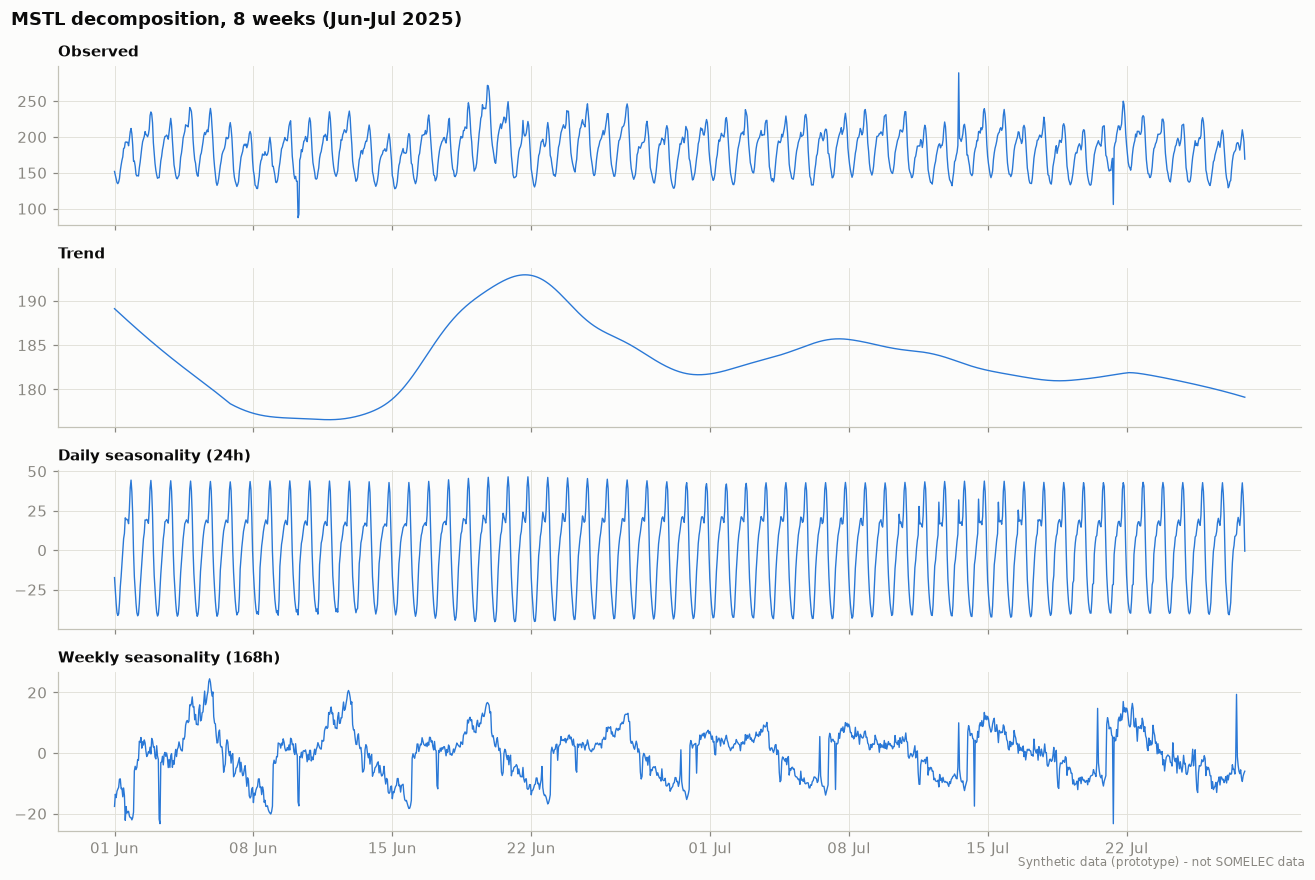

In [10]:
from statsmodels.tsa.seasonal import MSTL
window = s["demand_mw"].loc["2025-06-01":"2025-07-27"]
res = MSTL(window, periods=(24, 168)).fit()
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, (name, comp) in zip(axes, [("Observed", res.observed), ("Trend", res.trend),
                                   ("Daily seasonality (24h)", res.seasonal["seasonal_24"]),
                                   ("Weekly seasonality (168h)", res.seasonal["seasonal_168"])]):
    ax.plot(comp.index, comp.values, color=SERIES[0], lw=0.9); ax.set_title(name, fontsize=10)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.suptitle("MSTL decomposition, 8 weeks (Jun-Jul 2025)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); add_source_note(fig); plt.show()

## 6. Relationship with weather

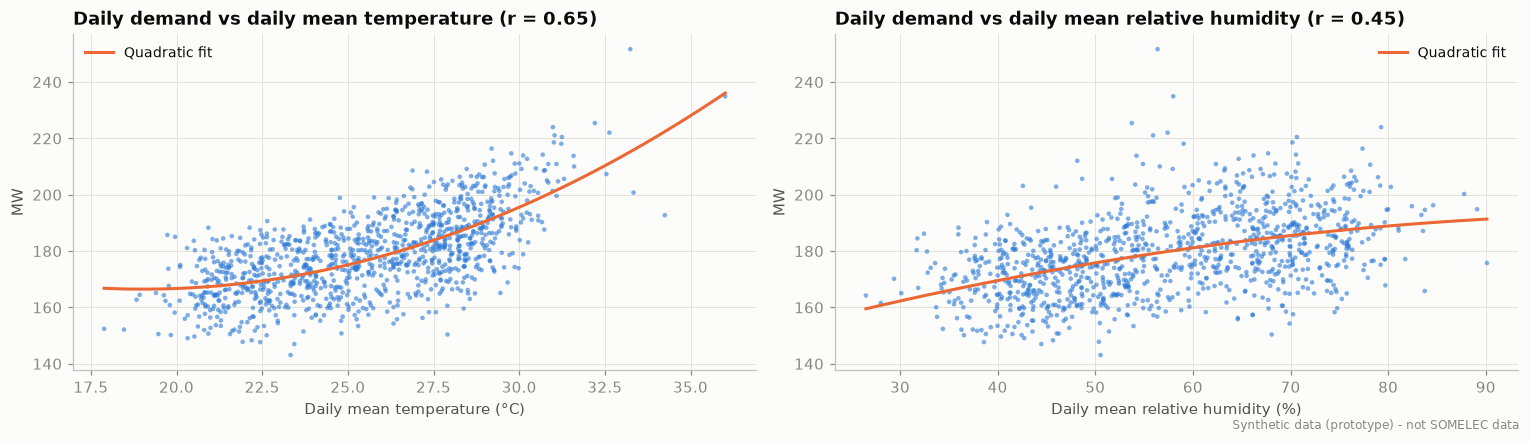

In [11]:
daily = s.resample("D").agg({"demand_mw": "mean", "temperature_c": "mean", "humidity": "mean",
                             "wind_speed": "mean", "cloud_cover": "mean"})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, label in [(axes[0], "temperature_c", "Daily mean temperature (°C)"),
                       (axes[1], "humidity", "Daily mean relative humidity (%)")]:
    ax.scatter(daily[col], daily["demand_mw"], s=9, color=SERIES[0], alpha=0.6, edgecolor="none")
    z = np.polyfit(daily[col], daily["demand_mw"], 2)
    xs = np.linspace(daily[col].min(), daily[col].max(), 100)
    ax.plot(xs, np.polyval(z, xs), color=SERIES[1], lw=2, label="Quadratic fit")
    r = daily[col].corr(daily["demand_mw"])
    ax.set_title(f"Daily demand vs {label.split('(')[0].lower().strip()} (r = {r:.2f})")
    ax.set_xlabel(label); ax.set_ylabel("MW"); ax.legend()
fig.tight_layout(); add_source_note(fig); plt.show()

In [12]:
corr_hourly = s.corr()["demand_mw"].drop("demand_mw")
corr_daily = daily.corr()["demand_mw"].drop("demand_mw")
pd.DataFrame({"hourly correlation": corr_hourly, "daily-mean correlation": corr_daily}).round(3)

,hourly correlation,daily-mean correlation
temperature_c,0.71,0.65
humidity,-0.08,0.45
wind_speed,0.46,-0.03
cloud_cover,0.12,0.27


Hourly correlations mix two effects: weather *and* the daily cycle (afternoons are hotter, drier and
windier, and also busier). Daily means remove the daily cycle and isolate the weather signal. That is why
humidity correlates weakly or negatively at hourly resolution while being part of the cooling-load driver.
The same confounding will appear in real data; tree-based models with calendar features handle it.

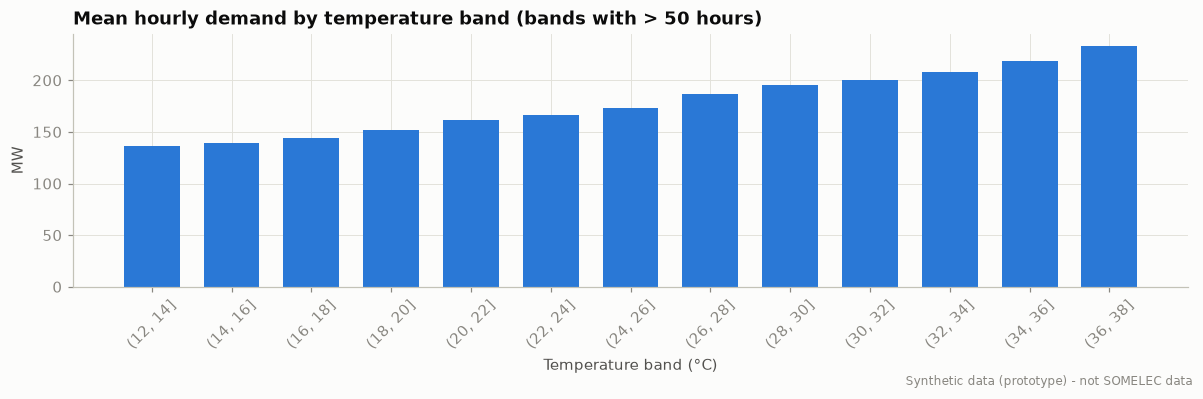

In [13]:
temp_bins = pd.cut(s["temperature_c"], bins=range(10, 44, 2))
tb = s.groupby(temp_bins, observed=True)["demand_mw"].agg(["mean", "count"])
tb = tb[tb["count"] > 50]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(range(len(tb)), tb["mean"], color=SERIES[0], width=0.7)
ax.set_xticks(range(len(tb)), [str(i) for i in tb.index], rotation=45)
ax.set_title("Mean hourly demand by temperature band (bands with > 50 hours)")
ax.set_xlabel("Temperature band (°C)"); ax.set_ylabel("MW")
fig.tight_layout(); add_source_note(fig); plt.show()

## 7. Peak demand

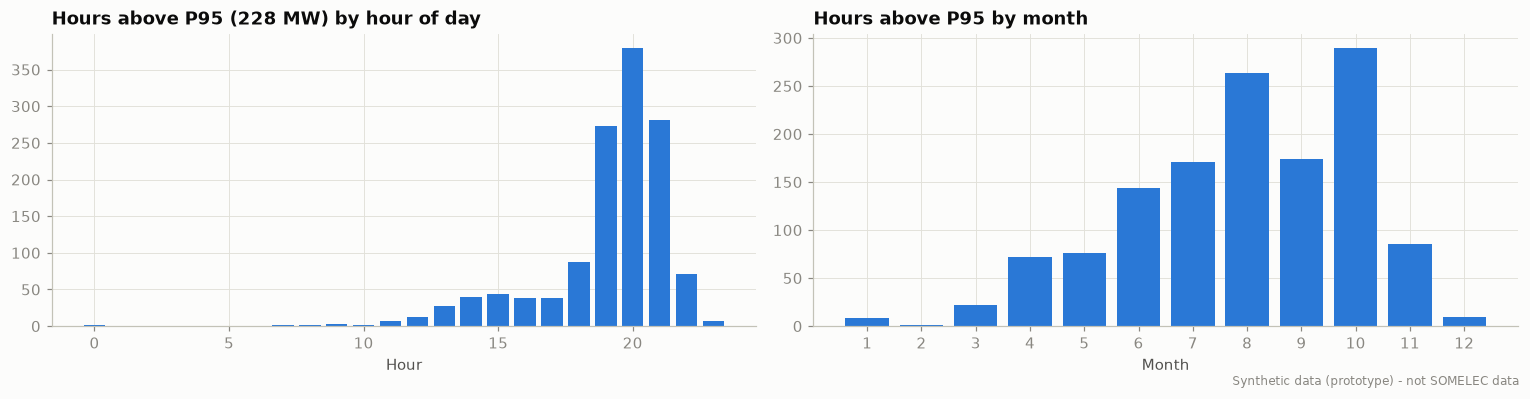

Global P95 threshold: 228.1 MW
Share of hours above the global P95, by calendar year:
timestamp
2023    2.3%
2024    2.9%
2025    5.9%
2026    8.3%


In [14]:
p95 = s["demand_mw"].quantile(0.95)
peaks = s[s["demand_mw"] >= p95]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
axes[0].bar(range(24), peaks.index.hour.value_counts().reindex(range(24), fill_value=0), color=SERIES[0])
axes[0].set_title(f"Hours above P95 ({p95:.0f} MW) by hour of day"); axes[0].set_xlabel("Hour")
axes[1].bar(range(1, 13), peaks.index.month.value_counts().reindex(range(1, 13), fill_value=0), color=SERIES[0])
axes[1].set_title("Hours above P95 by month"); axes[1].set_xlabel("Month"); axes[1].set_xticks(range(1, 13))
fig.tight_layout(); add_source_note(fig); plt.show()

by_year = s["demand_mw"].groupby(s.index.year).apply(lambda x: (x >= p95).mean())
print(f"Global P95 threshold: {p95:.1f} MW")
print("Share of hours above the global P95, by calendar year:"); print(by_year.map("{:.1%}".format).to_string())

With a growing trend, a *fixed* threshold computed on the whole history puts most exceedances in
the most recent period. The peak-detection module (Phase 11) therefore uses a percentile over a **trailing
window** (the last 365 days before the forecast) rather than over the full history.

## 8. Anomalies

In [15]:
outlier_check = next(c for c in report.checks if c.name == "demand_outliers")
print(outlier_check.message)
print("Injected ground-truth events:", events["event_type"].value_counts().to_dict())

127 potential demand outliers (|robust z| > 5.0)
Injected ground-truth events: {'load_shedding': 45, 'heatwave': 21, 'meter_glitch': 20, 'demand_surge': 14}


In [16]:
# Recompute robust z-scores to compare flags with the synthetic ground truth.
hour = s.index.hour
med = s["demand_mw"].groupby(hour).transform(lambda x: x.rolling(15, center=True, min_periods=5).median())
resid = s["demand_mw"] - med
mad = resid.abs().groupby(hour).transform(lambda x: x.rolling(29, center=True, min_periods=5).median())
z = 0.6745 * resid / mad
flag_set = set(z[z.abs() > 5].index)

rows = []
for kind, g in events.groupby("event_type"):
    hits = sum(any(t in flag_set for t in pd.date_range(e.start, e.end, freq="h")) for e in g.itertuples())
    rows.append({"event_type": kind, "injected": len(g), "detected_by_outlier_check": hits})
pd.DataFrame(rows)

,event_type,injected,detected_by_outlier_check
0,demand_surge,14,1
1,heatwave,21,8
2,load_shedding,45,38
3,meter_glitch,20,19


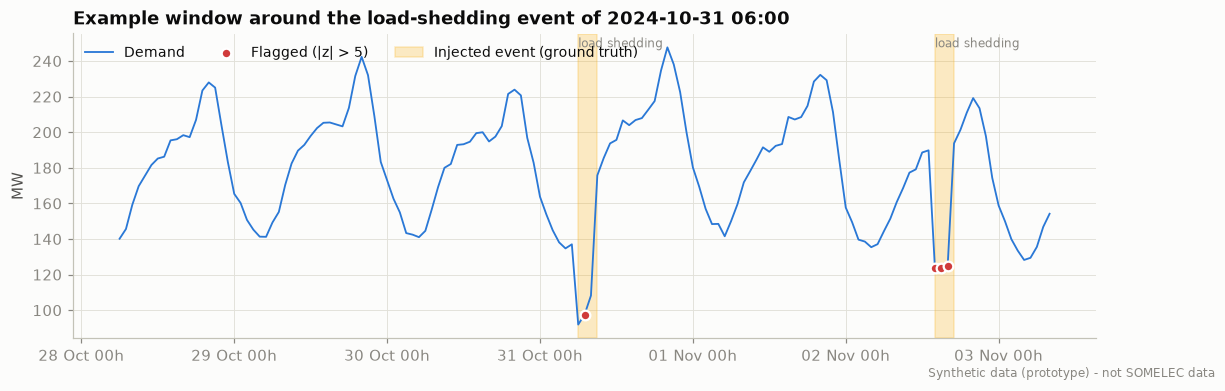

In [17]:
shed = events[events.event_type == "load_shedding"].iloc[len(events[events.event_type == "load_shedding"]) // 2]
win = s.loc[shed.start - pd.Timedelta("3D"): shed.end + pd.Timedelta("3D")]
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(win.index, win["demand_mw"], color=SERIES[0], lw=1.2, label="Demand")
fl = win.index[win.index.isin(list(flag_set))]
ax.scatter(fl, win.loc[fl, "demand_mw"], s=40, color=STATUS["critical"], zorder=3, label="Flagged (|z| > 5)",
           edgecolor="white", linewidth=1.5)
in_win = events[(events.end >= win.index.min()) & (events.start <= win.index.max()) & (events.event_type != "heatwave")]
for j, e in enumerate(in_win.itertuples()):
    ax.axvspan(e.start, e.end + pd.Timedelta("1h"), color=STATUS["warning"], alpha=0.25,
               label="Injected event (ground truth)" if j == 0 else None)
    ax.annotate(e.event_type.replace("_", " "), (e.start, win["demand_mw"].max()), fontsize=8, color=INK_MUTED)
ax.set_title(f"Example window around the load-shedding event of {shed.start:%Y-%m-%d %H:%M}")
ax.set_ylabel("MW"); ax.legend(loc="upper left", ncols=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Hh"))
add_source_note(fig); plt.show()

## 9. Findings

Computed on the **synthetic** dataset. These describe the simulator, not Nouakchott; the same analysis must be re-run on real data.

1. **Data quality**: 26,304 hourly rows, no gaps, no nulls, no duplicates. The outlier check flags 127 hours.
   Compared with the ground truth, it recovers most meter glitches (19/20) and load-shedding events (38/45),
   but few demand surges (1/14), which are gradual and close to normal variability.
2. **Strong daily cycle**: trough around 04:00, evening peak around 20:00. The daily amplitude is much larger than the
   weekly or seasonal effects. Lags 1-3 and 24 carry most of the short-term information.
3. **Weekly cycle**: the weekend (Sat-Sun) is ~7.5 % below weekdays and Friday sits in between. Lag 168 (0.90) is as
   informative as lag 24 (0.90), so both must be features.
4. **Seasonality and weather**: the hot, humid months (Jun-Oct) are ~10-13 % above the coolest month. Daily demand
   increases non-linearly with temperature (r = 0.65 on daily means). Hourly correlations are confounded by the
   daily cycle (e.g. humidity is -0.08 hourly but +0.45 on daily means), so models need calendar and weather together.
5. **Trend**: +10.7 % between the first and the last 12 months. A tree model cannot extrapolate a level it has
   never seen, which argues for **lag/rolling features** (they carry the current level) and for evaluating on the most
   recent period.
6. **Peaks**: exceedances of a global P95 concentrate in the evening, in the hot season and in recent years
   (2.9 % of 2024 hours vs 8.3 % of 2026 hours). A fixed historical threshold is therefore biased; peak detection
   will use a **trailing 365-day percentile**.
7. **Anomalies stay in the data**: they are real-world-like behaviour (load shedding affects *served* demand). They
   are kept for training and evaluation, and the event log allows measuring their impact.

**Implications for modelling**: lags {1, 2, 3, 6, 12, 24, 48, 72, 168} and rolling statistics up to 7 days, calendar
features, weather features, chronological validation on the most recent months, and baselines at lags 1, 24 and 168.